# Week 2: Exploratory Data Analysis and Visualization
## Titanic Passenger Dataset
**Objective:** Explore the dataset, summarize its characteristics, investigate relationships, and communicate patterns through clearly labelled visualizations. This is descriptive analysis and does not establish causation.

## 1. Load libraries and data
Place `raw_titanic.csv` beside this notebook. If it is missing, the notebook downloads the public dataset.

In [13]:
from pathlib import Path
import urllib.request, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Save every chart in this folder as well as displaying it below its cell.
plot_dir = Path("eda_plots_ouputs")
plot_dir.mkdir(exist_ok=True)

data_path = Path("raw_titanic.csv")
if not data_path.exists():
    urllib.request.urlretrieve("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv", data_path)
df = pd.read_csv(data_path)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Initial inspection
Review data types, missing values, matching rows, and descriptive statistics before interpreting patterns.

In [14]:
print("Shape:", df.shape)
display(df.dtypes.rename("data_type").to_frame())
display(df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print("Exact matching rows:", df.duplicated().sum())
display(df.describe(include="all").T)

Shape: (891, 15)


,data_type
survived,int64
pclass,int64
sex,str
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,str
class,str
who,str


,missing_count
deck,688
age,177
embarked,2
embark_town,2
survived,0
pclass,0
sex,0
sibsp,0
parch,0
fare,0


Exact matching rows: 107


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Prepare a working copy
Trim surrounding whitespace in text fields while keeping the raw DataFrame unchanged. Missing values are not globally dropped.

In [15]:
eda = df.copy()
for col in eda.select_dtypes(include=["object", "str"]).columns:
    eda[col] = eda[col].astype("string").str.strip()
print("Overall survival rate:", round(eda["survived"].mean(), 3))
print("Median observed age:", round(eda["age"].median(), 2))
print("Median fare:", round(eda["fare"].median(), 2))

Overall survival rate: 0.384
Median observed age: 28.0
Median fare: 14.45


## 4. Passenger age distribution

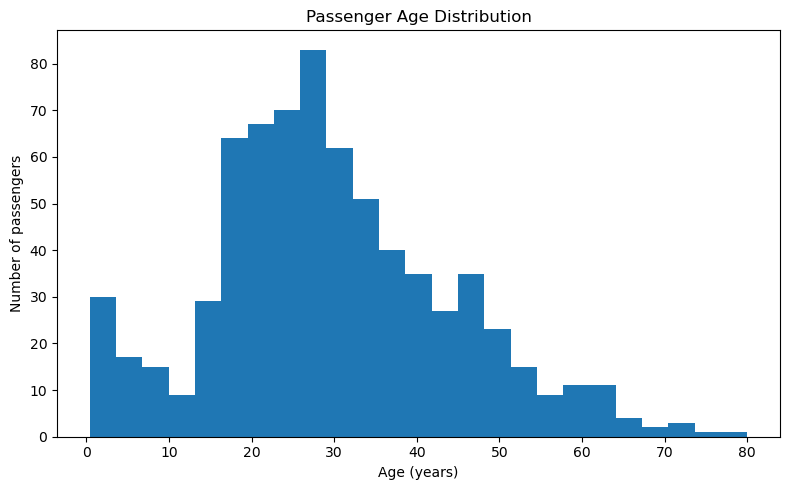

In [16]:
plt.figure(figsize=(8,5))
plt.hist(eda["age"].dropna(), bins=25)
plt.title("Passenger Age Distribution"); plt.xlabel("Age (years)"); plt.ylabel("Number of passengers")
plt.tight_layout(); plt.savefig(plot_dir / "age_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Observed ages are concentrated among young and middle-aged adults, with fewer older passengers and some children. Because some age values are missing, this chart describes observed ages only.

## 5. Passenger fare distribution

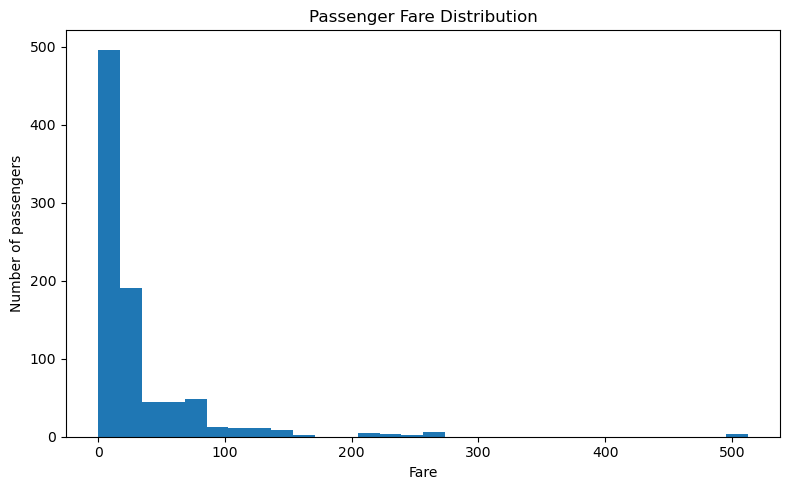

In [17]:
plt.figure(figsize=(8,5))
plt.hist(eda["fare"].dropna(), bins=30)
plt.title("Passenger Fare Distribution"); plt.xlabel("Fare"); plt.ylabel("Number of passengers")
plt.tight_layout(); plt.savefig(plot_dir / "fare_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Fares are right-skewed: many passengers paid relatively low fares, while fewer paid much higher fares. The chart alone cannot explain why the high fares occurred.

## 6. Survival rate by sex

,passengers,survival_rate
sex,,
female,314,0.742038
male,577,0.188908


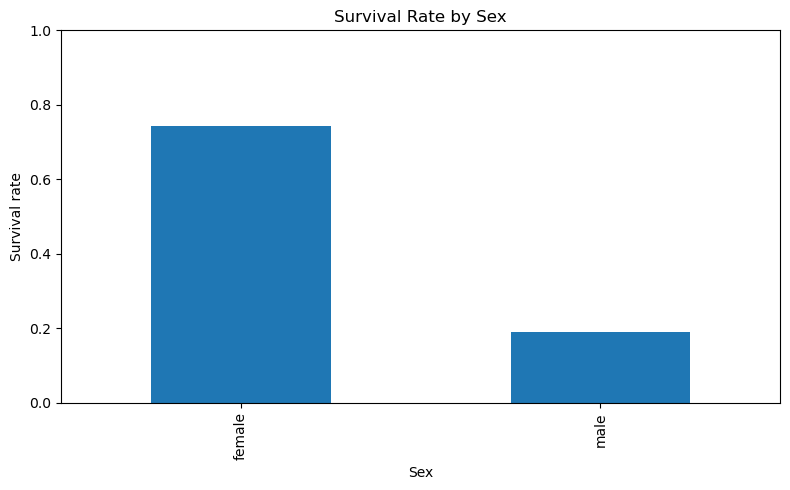

In [18]:
rates = eda.groupby("sex")["survived"].mean()
display(eda.groupby("sex")["survived"].agg(["count","mean"]).rename(columns={"count":"passengers","mean":"survival_rate"}))
rates.plot(kind="bar", figsize=(8,5))
plt.title("Survival Rate by Sex"); plt.xlabel("Sex"); plt.ylabel("Survival rate"); plt.ylim(0,1)
plt.tight_layout(); plt.savefig(plot_dir / "survival_by_sex.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Survival proportions differ by sex in this dataset, with women showing a higher observed survival rate than men. This is an association, not proof of a single cause.

## 7. Survival rate by passenger class

,passengers,survival_rate
pclass,,
1,216,0.629630
2,184,0.472826
3,491,0.242363


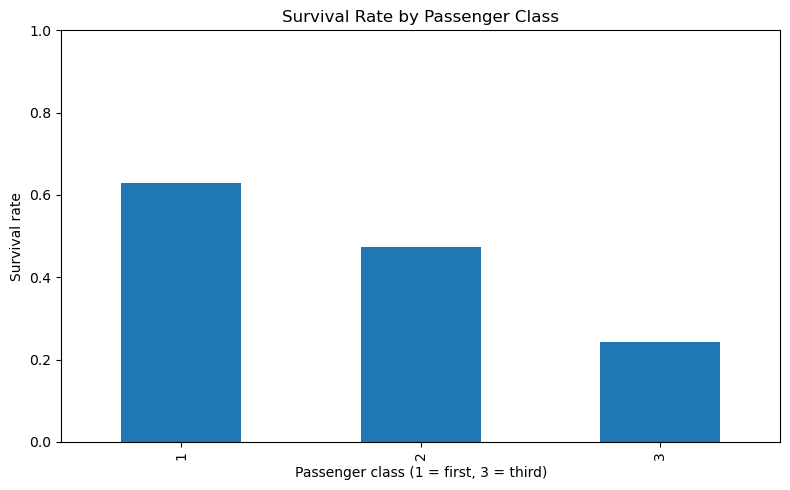

In [19]:
display(eda.groupby("pclass")["survived"].agg(["count","mean"]).rename(columns={"count":"passengers","mean":"survival_rate"}))
eda.groupby("pclass")["survived"].mean().plot(kind="bar", figsize=(8,5))
plt.title("Survival Rate by Passenger Class"); plt.xlabel("Passenger class (1 = first, 3 = third)")
plt.ylabel("Survival rate"); plt.ylim(0,1); plt.tight_layout(); plt.savefig(plot_dir / "survival_by_class.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Survival proportions generally differ across passenger classes, with first class higher and third class lower. Class may reflect access and social differences, but this chart cannot isolate those explanations.

## 8. Correlation among numeric variables
Pearson correlation describes linear association. It does not establish causation, and numeric codes for categories need cautious interpretation.

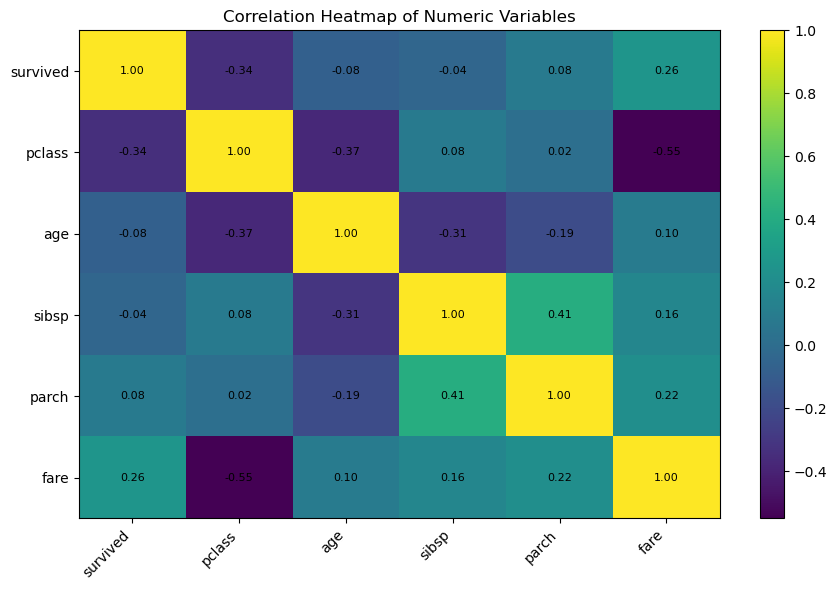

In [20]:
numeric = eda.select_dtypes(include=np.number)
corr = numeric.corr()
fig, ax = plt.subplots(figsize=(9,6))
im = ax.imshow(corr, aspect="auto")
ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns)), labels=corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation Heatmap of Numeric Variables")
fig.colorbar(im, ax=ax); fig.tight_layout(); fig.savefig(plot_dir / "correlation_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Use the heatmap to identify positive and negative linear associations. Correlations involving passenger class or survival should be interpreted cautiously because some variables are coded categories or binary outcomes.

## 9. Family size and survival
Family size is derived as `sibsp + parch + 1`, including the passenger.

,passengers,survival_rate
family_size,,
1,537,0.303538
2,161,0.552795
3,102,0.578431
4,29,0.724138
5,15,0.200000
6,22,0.136364
7,12,0.333333
8,6,0.000000
11,7,0.000000


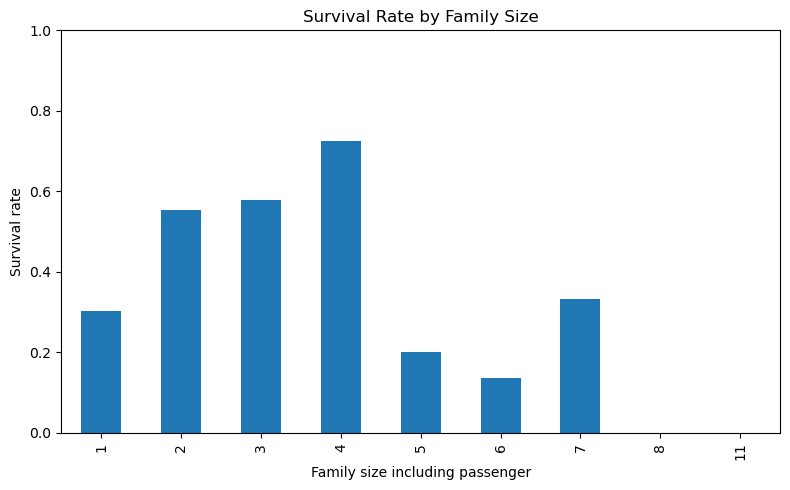

In [21]:
eda["family_size"] = eda["sibsp"].fillna(0) + eda["parch"].fillna(0) + 1
family_summary = eda.groupby("family_size")["survived"].agg(["count","mean"]).rename(columns={"count":"passengers","mean":"survival_rate"})
display(family_summary)
family_summary["survival_rate"].plot(kind="bar", figsize=(8,5))
plt.title("Survival Rate by Family Size"); plt.xlabel("Family size including passenger")
plt.ylabel("Survival rate"); plt.ylim(0,1); plt.tight_layout(); plt.savefig(plot_dir / "survival_by_family_size.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Survival proportions can vary by family size. Groups with few passengers should be treated cautiously because their rates are based on small samples. This is descriptive, not causal.

## 10. Survival rate by embarkation port

,passengers,survival_rate
embarked,,
C,168,0.553571
Q,77,0.389610
S,644,0.336957


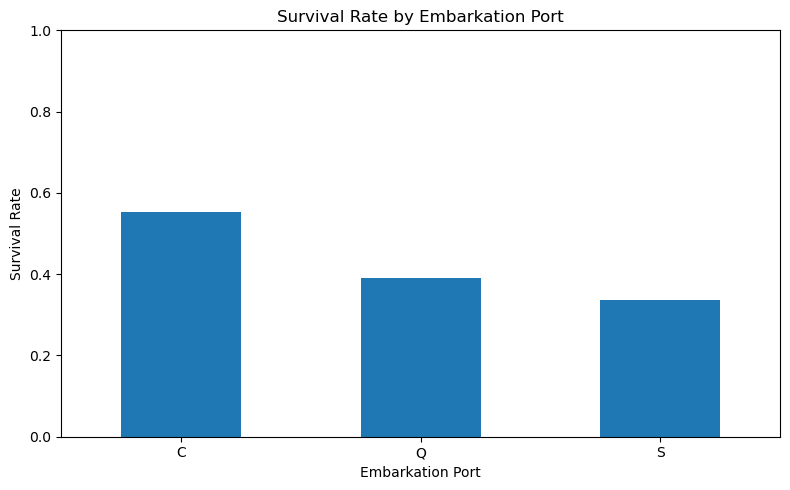

In [22]:
display(
    eda.dropna(subset=["embarked"])
       .groupby("embarked")["survived"]
       .agg(["count", "mean"])
       .rename(columns={"count": "passengers", "mean": "survival_rate"})
)

embark_survival = (
    eda.dropna(subset=["embarked"])
       .groupby("embarked")["survived"]
       .mean()
)

embark_survival.plot(kind="bar", figsize=(8, 5))
plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(plot_dir / "survival_by_embarkation.png",
            dpi=300, bbox_inches="tight")
plt.show()

**Interpretation:** Observed survival proportions differ by embarkation port. Differences may reflect passenger class and other group characteristics rather than an effect of the port itself.

## 11. Key findings and limitations
- Age is concentrated among younger adults; fare is right-skewed.
- Observed survival proportions differ by sex and passenger class.
- Family size and embarkation port offer additional group comparisons.
- The analysis is descriptive and does not establish causal explanations.
- Missing values and exact matching rows should be considered when interpreting results.

## 12. Export summary outputs

In [24]:
# Save charts and keep the CSV/JSON summary exports for your assignment.
from pathlib import Path
import json

# Save exported tables in a separate folder to keep the project organized.
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Descriptive statistics for numeric columns
descriptive_stats.to_csv(
    output_dir / "descriptive_statistics.csv", index=False
)

missing_values.to_csv(
    output_dir / "missing_values.csv", index=False
)

# Missing-value counts for every column
missing_values = eda.isna().sum().rename("missing_count").to_frame()
missing_values.to_csv(output_dir / "missing_values.csv")

# Summary details for the report
summary = {
    "dataset_shape": [int(df.shape[0]), int(df.shape[1])],
    "missing_values": {str(k): int(v) for k, v in df.isna().sum().items()},
    "exact_matching_rows": int(df.duplicated().sum()),
    "overall_survival_rate": float(df["survived"].mean()),
    "median_observed_age": float(df["age"].median()),
    "median_fare": float(df["fare"].median())
}
with open(output_dir / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Chart folder:", plot_dir.resolve())
print("Saved chart files:", sorted(p.name for p in plot_dir.glob("*.png")))
print("Summary files saved in:", output_dir.resolve())
print(sorted(p.name for p in output_dir.iterdir()))

Chart folder: C:\Users\Tharun\Internship\Week 2 Task Exploratory Data Analysis and Visualization\eda_plots_ouputs
Saved chart files: ['age_distribution.png', 'correlation_heatmap.png', 'fare_distribution.png', 'survival_by_class.png', 'survival_by_embarkation.png', 'survival_by_family_size.png', 'survival_by_sex.png']
Summary files saved in: C:\Users\Tharun\Internship\Week 2 Task Exploratory Data Analysis and Visualization\outputs
['descriptive_statistics.csv', 'eda_summary.json', 'missing_values.csv']


## Conclusion
This EDA uses summary statistics and multiple visualizations to examine passenger age and fare distributions and survival proportions across groups. The findings can guide further analysis, but observed associations should not be interpreted as causal explanations.